## Titanic Survival Analysis

#### Library and Dataset Import

In [5]:
import pandas as pd
import numpy as np
titanic = pd.read_csv("titanic.csv")
print("Kütüphaneler ve dataset içe aktarıldı.")

Kütüphaneler ve dataset içe aktarıldı.


#### Exploratory Data Analysis (EDA)

In [6]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
titanic.shape #891 yolcu 12 bilgi

(891, 12)

In [8]:
titanic.info() # demekki yaş,kabin no,bindiği limanda eksik bilgiler var

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
titanic.isnull().sum() #yas:177,kabin no:687,liman bilgisi:2 eksik değer bulunuyor.

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
titanic.nunique() #her sütunda kaç farklı değer olduğunu gösterir.

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [12]:
titanic["Survived"].value_counts()   #hayatta kalan ve kurtulan

Survived
0    549
1    342
Name: count, dtype: int64

In [13]:
titanic["Sex"].value_counts()   #cinsiyet 

Sex
male      577
female    314
Name: count, dtype: int64

In [14]:
titanic["Pclass"].value_counts() # sınıfların sayısı

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [15]:
titanic["Age"].value_counts() #yaşlardan kaç tane var.

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1
74.00     1
Name: count, Length: 88, dtype: int64

In [16]:
titanic["Embarked"].value_counts() #Hangi limandan bindikleri bilgisi çoğunluk UK ve France dan binmiş

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [17]:
titanic.groupby("Sex")["Survived"].mean() #Kadınlar daha çok kurtulmuş

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [18]:
titanic.groupby("Pclass")["Survived"].mean() #Üst sınıf bilet hayatta kalma şansı daha yüksek

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [19]:
titanic.groupby("Embarked")["Survived"].mean() #C limanında binenler ilginç şekilde hayatta kalma oranı yüksek.Fransadan binenler yani.


Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

In [20]:
titanic.tail() # Son 5 satırı gösterir.

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [21]:
titanic.groupby("Age")["Survived"].mean()

Age
0.42     1.0
0.67     1.0
0.75     1.0
0.83     1.0
0.92     1.0
        ... 
70.00    0.0
70.50    0.0
71.00    0.0
74.00    0.0
80.00    1.0
Name: Survived, Length: 88, dtype: float64

In [22]:
titanic['AgeGroup'] = pd.cut(titanic['Age'], bins=[0, 12, 18, 35, 60, 100],                              ##Bir özelliği gruplara ayırma
                          labels=['Çocuk', 'Genç', 'Genç Yetişkin', 'Yetişkin', 'Yaşlı'])
titanic.groupby('AgeGroup', observed=False)['Survived'].mean()        # Çocukların yaşama oranı yüksek ihtiyarların az.
                                                                    #  genç ve yetişkinlerinde birbirine yakın.


AgeGroup
Çocuk            0.579710
Genç             0.428571
Genç Yetişkin    0.382682
Yetişkin         0.400000
Yaşlı            0.227273
Name: Survived, dtype: float64

In [23]:
titanic.groupby("AgeGroup").size() 

C:\Users\enesc\AppData\Local\Temp\ipykernel_10664\2839040172.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby("AgeGroup").size()


AgeGroup
Çocuk             69
Genç              70
Genç Yetişkin    358
Yetişkin         195
Yaşlı             22
dtype: int64

In [24]:
survival= titanic.groupby("Embarked")["Survived"].agg(                   ## agg komutuyla birden fazla özet fonksiyonu çalıştırıyoruz.
    total_count="count",  # Toplam yolcu sayısı
    survived_sum="sum"
)

# Ölenlerin sayısını da ekleyelim
survival["died"] = survival["total_count"] - survival["survived_sum"]

print(survival)

# buda bir yöntem tablo için
pd.crosstab(titanic["Embarked"], [titanic["Survived"],titanic["Sex"]])                   ## buda kısa yöntem çaprazlama


          total_count  survived_sum  died
Embarked                                 
C                 168            93    75
Q                  77            30    47
S                 644           217   427


Survived      0           1     
Sex      female male female male
Embarked                        
C             9   66     64   29
Q             9   38     27    3
S            63  364    140   77

#### Missing Value Imputation

In [25]:
titanic['Age'] = titanic.groupby(['Pclass', 'Sex'])['Age'].transform(lambda x: x.fillna(x.median()))    ##transform veri doldurmada kullanılır.

In [26]:
titanic["HasCabin"]= titanic["Cabin"].notnull().astype(int)    ##drop silme işlemlerinde kullanılıyor.
titanic=titanic.drop(columns=["Cabin"])                        ## burada cabinin ne olduğu değilde kabin nnosunun olup olmamasını baz aldık.İlişkili olabilir survived ile

In [27]:
titanic["Embarked"]=titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])  ## fillna null değerlerini doldurmak  için
                                                                               ## mode en çok kullanılan değeri verir.

#### Outlier Handling

In [28]:
# Amaç: "normal aralık" için bir sınır çizmek. Bunu şöyle yapıyoruz:

# Q1 (7.91): Yolcuların %25'i bundan daha az ücret ödemiş (ucuz uçta kalan çeyrek)
# Q3 (31.00): Yolcuların %75'i bundan daha az ücret ödemiş (yani en pahalı %25 bunun üstünde)
# IQR = Q3 - Q1 = 23.09: Bu, verinin "ortadaki kalabalık kısmının" genişliği — yani insanların çoğunluğunun ödediği fiyat aralığının büyüklüğü
# Üst sınır = Q3 + 1.5 × IQR = 31 + 1.5×23.09 = 65.63

# Bunun mantığı şu: "Ortadaki normal aralığın 1.5 katından daha fazla uzaklaşan bir değer varsa, bu artık sıradan bir fiyat değil, aşırı uçta bir değer sayılır." 1.5 katsayısı istatistikte genel kabul görmüş standart bir eşik, herkes bunu kullanır.

#### Feature Engineering

In [29]:
titanic["FamilySize"]=titanic["SibSp"]+titanic["Parch"] +1  # direk aile sayısı değişkeni oluşturk 2 tnesiyle uğraşmak yerine

In [30]:
titanic["IsAlone"]=(titanic["FamilySize"]==1).astype(int)  # Yanlız mı değil mi bu bize fikir verebilir.Kişi yanlızsa daha münferit hareket eder.

In [31]:
titanic["Title"] = titanic["Name"].str.extract(r"([A-Za-z]+)\.")    #Ünvan featuresinin oluşturulması ve Ünvanların kaçar tane oldukları
titanic["Title"].value_counts()

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Mlle          2
Major         2
Col           2
Countess      1
Capt          1
Ms            1
Sir           1
Lady          1
Mme           1
Don           1
Jonkheer      1
Name: count, dtype: int64

#### Post-Feature Engineering EDA

In [32]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeGroup,HasCabin,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Genç Yetişkin,0,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Yetişkin,1,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Genç Yetişkin,0,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Genç Yetişkin,1,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Genç Yetişkin,0,1,1,Mr


In [33]:
titanic.groupby("FamilySize")["Survived"].mean()   #Oluşturduğumuz yeni bir özelliğin hayatta kalma oranları

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64

In [34]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.112424,0.523008,0.381594,32.204208,0.228956,1.904602,0.602694
std,257.353842,0.486592,0.836071,13.304424,1.102743,0.806057,49.693429,0.420397,1.613459,0.489615
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,223.500000,0.000000,2.000000,21.500000,0.000000,0.000000,7.910400,0.000000,1.000000,0.000000
50%,446.000000,0.000000,3.000000,26.000000,0.000000,0.000000,14.454200,0.000000,1.000000,1.000000
75%,668.500000,1.000000,3.000000,36.000000,1.000000,0.000000,31.000000,0.000000,2.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,1.000000,11.000000,1.000000


In [35]:
titanic.groupby("IsAlone")["Survived"].mean()           #Oluşturduğumuz featurenin hayatta kalma oranları

IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64

In [36]:
titanic["Title"].value_counts()               #Ünvanların kaçar tane oldukları

Title
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Mlle          2
Major         2
Col           2
Countess      1
Capt          1
Ms            1
Sir           1
Lady          1
Mme           1
Don           1
Jonkheer      1
Name: count, dtype: int64

In [37]:
titanic.groupby("Title")["Survived"].mean()     # Ünvana göre hayatta kalma oranları

Title
Capt        0.000000
Col         0.500000
Countess    1.000000
Don         0.000000
Dr          0.428571
Jonkheer    0.000000
Lady        1.000000
Major       0.500000
Master      0.575000
Miss        0.697802
Mlle        1.000000
Mme         1.000000
Mr          0.156673
Mrs         0.792000
Ms          1.000000
Rev         0.000000
Sir         1.000000
Name: Survived, dtype: float64

In [38]:
summary=titanic.groupby("Title")["Survived"].agg(['mean', 'count'])   # agg komutu ile grupladığımız featureleri birden fazla kıyas yapabiliyoruz. mean,count vb.
summary=summary.sort_values("count",ascending=False)                  # sort_values ile counta göre büyükten küçüğe sıraladım.
summary.head()

,mean,count
Title,,
Mr,0.156673,517
Miss,0.697802,182
Mrs,0.792000,125
Master,0.575000,40
Dr,0.428571,7


In [39]:
titanic[titanic["Title"] == "Mr"]["Survived"].value_counts()   #sadec mr olanlar
                                        # Demek ki Mr yani Erkeklerin ekseriyeti ölmüş,kadınların çoğunluğu kurtulmuş,çocuklarında aynı şekilde çoğu kurtulmuş.
                                        # Ünvana göre yaptığımız çıkarım.

Survived
0    436
1     81
Name: count, dtype: int64

####  Rare Category Grouping (in Feature Engineering)

In [40]:
rare_titles= titanic["Title"].value_counts()[titanic["Title"].value_counts() <10 ].index   # 10 kereden az geçen değerleri rare_titlesa atıyoruz
titanic["Title"] = titanic["Title"].replace(rare_titles,"Rare")                            # replace fonksiyonu değerleri değiştirmek için kullanıyoruz.Az geçenleri tek bir ad veriyoruz Rare
titanic["Title"] = titanic["Title"].replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"})       #  Birbirine benzeyen isimleri birleştiriyoruz .Aynı anlama gelen eng fr birleşimi

                                                                                           # İşlem yaptığın zaman yani bir değişikilik ,bir oluşum incelemek dışındaki şeyleri hep eşitlemen lazım.
                                                                                           # Çünkü pandas kütüphanesi gereği yeni bir değerler dönüyor onu df e kaydetmek için.

#### Categorical Variable Encoding (Encoding)

In [41]:
titanic["Sex"] = titanic["Sex"].map({"male":0,"female":1})  # Encoding işlemi :2 kategorikler için uygundur 0-1
                                                            # Model için herşey sayıdır dolayısıyla bizde buna yardım etmeliyiz.

In [42]:
titanic = pd.get_dummies(titanic,columns=["Embarked","Title"],drop_first=True)   # Burada ise 3+ kategori için nasıl encoding yapacağımız var.
                                                                                 # Embarken_Q,Embarked_S diye bağımsız sütunlar kurar.
                                                                                 # drop_first =True ise bir adeti siler çünkü diğerlerinin yokluğu zaten yazılmayana delalet eder.Q=0, S=0 ise C dir bu.Gereksiz sütun olmaz.
                                                                                 # Title de aynı şekilde encoding yapılıyor .

In [43]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,AgeGroup,HasCabin,FamilySize,IsAlone,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,Genç Yetişkin,0,2,0,False,True,False,True,False,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,Yetişkin,1,2,0,False,False,False,False,True,False
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,Genç Yetişkin,0,1,1,False,True,True,False,False,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,Genç Yetişkin,1,2,0,False,True,False,False,True,False
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,Genç Yetişkin,0,1,1,False,True,False,True,False,False


In [44]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    int64   
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  AgeGroup     714 non-null    category
 11  HasCabin     891 non-null    int32   
 12  FamilySize   891 non-null    int64   
 13  IsAlone      891 non-null    int32   
 14  Embarked_Q   891 non-null    bool    
 15  Embarked_S   891 non-null    bool    
 16  Title_Miss   891 non-null    bool    
 17  Title_Mr     891 non-null    bool    
 18  Title_Mrs    891 non-null    b

#### Feature Selection

In [45]:
titanic =titanic.drop(columns=["PassengerId","Name","Ticket","AgeGroup"]) # PassengerId survived ile bir alakası yok.
                                                                       # Name den zaten Title çıkardık diğeri işe yaramaz.
                                                                       # Ticket kullanışsız bir veri
                                                                       # Cabin zaten HasCabin e çevirdik
                                                                       # AgeGroup sadece analiz için oluşturmuştuk.
                                               # encoding ve drop işlemlerinde titanic= diye eşitleme yapılır çünkü genel sütunlar işlemi yapılır.

In [46]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   HasCabin    891 non-null    int32  
 8   FamilySize  891 non-null    int64  
 9   IsAlone     891 non-null    int32  
 10  Embarked_Q  891 non-null    bool   
 11  Embarked_S  891 non-null    bool   
 12  Title_Miss  891 non-null    bool   
 13  Title_Mr    891 non-null    bool   
 14  Title_Mrs   891 non-null    bool   
 15  Title_Rare  891 non-null    bool   
dtypes: bool(6), float64(2), int32(2), int64(6)
memory usage: 68.0 KB


#### Train-Test Split

In [47]:
from sklearn.model_selection import train_test_split

x=titanic.drop(columns=["Survived"])          # Girdi değişkenleri ,survived hariç yani
y= titanic["Survived"]                        # Hedef değişkeni ,tahmin edeceğimiz değişken yani survived

x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)  # Yüzde 20sini teste ayırdık.Burda model için verileri böldük.


In [48]:
print(f"Toplam veri: {len(titanic)} satır")
print(f"X_train boyutu: {x_train.shape}")
print(f"X_test boyutu: {x_test.shape}")
print(f"y_train'de hayatta kalma oranı: {y_train.mean():.3f}")
print(f"y_test'te hayatta kalma oranı: {y_test.mean():.3f}")
print(f"\nX_train sütunları: {list(x_train.columns)}")

Toplam veri: 891 satır
X_train boyutu: (712, 15)
X_test boyutu: (179, 15)
y_train'de hayatta kalma oranı: 0.376
y_test'te hayatta kalma oranı: 0.413

X_train sütunları: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


#### Model Training

In [49]:
from sklearn.linear_model import LogisticRegression

model= LogisticRegression(max_iter=1000) # Ml modelini seçiyorum

model.fit(x_train,y_train)   # modeli eğitiyoruz
print("Model eğitimi tamamlandı")

Model eğitimi tamamlandı


In [50]:
y_pred= model.predict(x_test)  #Şimdi eğittiğimiz modeli tahmin etmeye çalışıyoruz.

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test,y_pred)           #yüzde kaç doğru ona bakıyoruz.
print(f"Doğruluk oranı: {acc:.4f}")

Doğruluk oranı: 0.8101


#### Model Evaluation And Cross Validation

In [51]:
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,f1_score,roc_auc_score)

# Önce tahminleri al
y_pred = model.predict(x_test)
y_proba = model.predict_proba(x_test)[:, 1]   # ROC-AUC için olasılık gerekiyor, y_pred değil

# Confusion Matrix
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print(f"\nAccuracy:  {accuracy_score(y_test, y_pred):.4f}")   #Dorğuluk-Kaçta kaç doğru
print(f"Precision: {precision_score(y_test, y_pred):.4f}")    # Kesinlik -hayatta kalır(pozitif) dediklerimin kaçı doğru?
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")      # Duyarlılık -Hayatta kalanların(Pozitif) kaçını buldun?
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")          #Precision + Recall dengesi
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")    #Ayırt etme gücü

# Hepsi bir arada, düzenli tablo halinde
print("\n=== classification_report ===")
print(classification_report(y_test, y_pred, target_names=['Hayatta Kalmadı', 'Hayatta Kaldı']))

=== Confusion Matrix ===
[[89 16]
 [18 56]]

Accuracy:  0.8101
Precision: 0.7778
Recall:    0.7568
F1-Score:  0.7671
ROC-AUC:   0.8901

=== classification_report ===
                 precision    recall  f1-score   support

Hayatta Kalmadı       0.83      0.85      0.84       105
  Hayatta Kaldı       0.78      0.76      0.77        74

       accuracy                           0.81       179
      macro avg       0.80      0.80      0.80       179
   weighted avg       0.81      0.81      0.81       179



In [52]:

   # Cross Validation ,çapraz doğrulama
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 1) CV stratejisini tanımla
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2) Cross-validation skorlarını al
scores = cross_val_score(
    estimator=model,
    X=x,
    y=y,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# 3) Sonuçları yazdır
print("Tek böölünmedeki Accuracy:  0.8101")
print("Her fold skoru:", scores)
print(f"Ortalama: {scores.mean():.4f}")
print(f"Std    : {scores.std():.4f}")

# model istikrarlıymış train test ayrımında

Tek böölünmedeki Accuracy:  0.8101
Her fold skoru: [0.83798883 0.8258427  0.80898876 0.83146067 0.8258427 ]
Ortalama: 0.8260
Std    : 0.0096


#### Random Forest 

In [53]:
from sklearn.ensemble import RandomForestClassifier    ## önce cross-validation yapmak lazım 

# Modeli oluştur
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Cross-validation ile istikrarını test et (Logistic Regression ile aynı yöntem)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_scores = cross_val_score(rf_model, x, y, cv=cv, scoring='accuracy',n_jobs=1)

print("Random Forest - Her fold'un skoru:", rf_scores)
print(f"Random Forest - Ortalama Accuracy: {rf_scores.mean():.4f}")
print(f"Random Forest - Standart Sapma:    {rf_scores.std():.4f}")

# Tek train/test bölünmesinde de dene (Logistic Regression ile karşılaştırmak için)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)
y_proba_rf = model.predict_proba(x_test)[:, 1]
# Confusion Matrix
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_rf))

print(f"\nAccuracy:  {accuracy_score(y_test, y_pred_rf):.4f}") 
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}") 
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")   
print(f"F1-Score:  {f1_score(y_test, y_pred_rf):.4f}")        
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_rf):.4f}")  

print(f"\nRandom Forest - Test seti Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\n=== Random Forest classification_report ===")
print(classification_report(y_test, y_pred_rf, target_names=['Hayatta Kalmadı', 'Hayatta Kaldı']))

Random Forest - Her fold'un skoru: [0.82681564 0.80337079 0.80898876 0.83707865 0.8258427 ]
Random Forest - Ortalama Accuracy: 0.8204
Random Forest - Standart Sapma:    0.0124
=== Confusion Matrix ===
[[89 16]
 [14 60]]

Accuracy:  0.8324
Precision: 0.7895
Recall:    0.8108
F1-Score:  0.8000
ROC-AUC:   0.8901

Random Forest - Test seti Accuracy: 0.8324

=== Random Forest classification_report ===
                 precision    recall  f1-score   support

Hayatta Kalmadı       0.86      0.85      0.86       105
  Hayatta Kaldı       0.79      0.81      0.80        74

       accuracy                           0.83       179
      macro avg       0.83      0.83      0.83       179
   weighted avg       0.83      0.83      0.83       179



#### Model Comparison

In [54]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

def metrikler(y_true, y_pred, y_proba):
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1-Score':  f1_score(y_true, y_pred),
        'ROC-AUC':   roc_auc_score(y_true, y_proba),
    }

df = pd.DataFrame({
    'Logistic Regression': metrikler(y_test, y_pred,    y_proba),
    'Random Forest':       metrikler(y_test, y_pred_rf, y_proba_rf),
})
df = (df * 100).round(2)
df['Fark (RF - LR)'] = (df['Random Forest'] - df['Logistic Regression']).round(2)
df


,Logistic Regression,Random Forest,Fark (RF - LR)
Accuracy,81.01,83.24,2.23
Precision,77.78,78.95,1.17
Recall,75.68,81.08,5.40
F1-Score,76.71,80.00,3.29
ROC-AUC,89.01,89.01,0.00


#### Hyperparameter Tuning

In [55]:
# Hiperparametre Ayarı -modeli iyileştirme-en iyi kombinasyonu GridSearchCV ile bulurz.

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1   # tüm işlemci çekirdeklerini kullan, hızlandırır
)

grid_search.fit(x_train, y_train)

print("En iyi parametreler:", grid_search.best_params_)
print(f"En iyi CV skoru: {grid_search.best_score_:.4f}")

# En iyi modeli test setinde dene
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(x_test)

En iyi parametreler: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
En iyi CV skoru: 0.8370


In [56]:
# En iyi modelin scoreları

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(x_test)
y_proba_best = best_model.predict_proba(x_test)[:, 1]

print("=== Optimize Edilmiş Model - Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred_best))

print(f"\nAccuracy:  {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_best):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_best):.4f}")

=== Optimize Edilmiş Model - Confusion Matrix ===
[[92 13]
 [17 57]]

Accuracy:  0.8324
Precision: 0.8143
Recall:    0.7703
F1-Score:  0.7917
ROC-AUC:   0.8960


#### Model Comparison

In [57]:
 ## en güçlü modelde dahil olmak üzere 3 modelimizi karşılaştırıyoruz.
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

def metrikler(y_true, y_pred, y_proba):
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall':    recall_score(y_true, y_pred),
        'F1-Score':  f1_score(y_true, y_pred),
        'ROC-AUC':   roc_auc_score(y_true, y_proba),
    }

housing = pd.DataFrame({
    'Logistic Regression': metrikler(y_test, y_pred,      y_proba),        # senin LR
    'Random Forest':       metrikler(y_test, y_pred_rf,   y_proba_rf),     # varsayılan RF
    'Optimize RF':         metrikler(y_test, y_pred_best, y_proba_best),   # GridSearch RF
})

# Yüzdeye çevir
housing = (housing * 100).round(2)

# Fark kolonları: her modeli LR ile karşılaştır
housing['Fark (RF - LR)']         = (housing['Random Forest'] - housing['Logistic Regression']).round(2)
housing['Fark (Opt RF - LR)']     = (housing['Optimize RF']   - housing['Logistic Regression']).round(2)
housing['Fark (Opt RF - RF)']     = (housing['Optimize RF']   - housing['Random Forest']).round(2)

housing   

,Logistic Regression,Random Forest,Optimize RF,Fark (RF - LR),Fark (Opt RF - LR),Fark (Opt RF - RF)
Accuracy,81.01,83.24,83.24,2.23,2.23,0.00
Precision,77.78,78.95,81.43,1.17,3.65,2.48
Recall,75.68,81.08,77.03,5.40,1.35,-4.05
F1-Score,76.71,80.00,79.17,3.29,2.46,-0.83
ROC-AUC,89.01,89.01,89.60,0.00,0.59,0.59


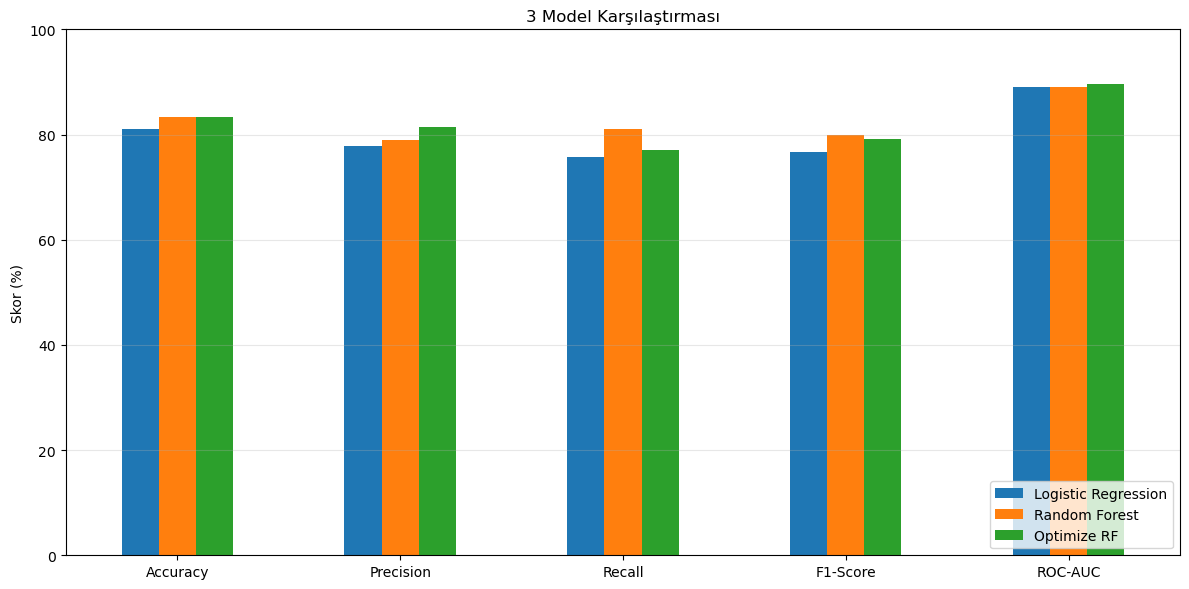

In [58]:
import matplotlib.pyplot as plt

housing_plot = housing[['Logistic Regression', 'Random Forest', 'Optimize RF']]

housing_plot.plot(kind='bar', figsize=(12, 6), rot=0)
plt.title('3 Model Karşılaştırması')
plt.ylabel('Skor (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()